# Empresa emergente de venta de productos alimentidcios

## Objetivos

### Estudio de embudo de ventas 
### Obcervcion de los resultados de una prueba A/A/B, para esto al equipo de diseño le gustaria cambiar las fuentes de toda la aplicacion, y la gerencia teme que los usuariospiensen el nuevo diseño es intimidante, por esta razon deciden tomar la decisión basada en los resultados del test. 

In [ ]:
# Librerias para el analisis 
import pandas as pd 
import datetime as dt 
import numpy as np 
import scipy.stats as stats 
import matplotlib.pyplot as plt 

## Paso 1 
### Abrir el archivo y leer informacion general 

In [ ]:
# usar el separador de tabulacion, un elelmento que se ve poco 'sep='\t''
market_global = pd.read_csv('/datasets/logs_exp_us.csv', sep='\t')

market_global.columns

Index(['EventName', 'DeviceIDHash', 'EventTimestamp', 'ExpId'], dtype='object')

In [ ]:
market_global.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  object
 1   DeviceIDHash    244126 non-null  int64 
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB


In [ ]:
print(market_global.head(5))

                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248


### Me parece una porcion de datos bastante generosa, suficiente para llevar acabo las instrucciones requeridas, hay que arreglar las mayusculas y cambiar algunos datos a su forma adecuada. 

## Paso 2 
### preparacion de los datos para el análisis

In [ ]:
# Cambio del nombre de las columnas 
market_global.rename(columns={'EventName': 'event', 'DeviceIDHash': 'user_id', 'EventTimestamp': 'hour_event', 'ExpId': 'exp_num'}, inplace=True)
print(market_global.columns)

Index(['event', 'user_id', 'hour_event', 'exp_num'], dtype='object')


In [ ]:
print("Numero de duplicados:",market_global.duplicated().sum())
print(market_global.isnull().sum())

Numero de duplicados: 413
event         0
user_id       0
hour_event    0
exp_num       0
dtype: int64


In [ ]:
global_clean = market_global.drop_duplicates().copy()
print("Numero de duplicados", global_clean.duplicated().sum())

Numero de duplicados 0


In [ ]:
global_clean = market_global.drop_duplicates().copy()
global_clean['date_event'] = pd.to_datetime(global_clean['hour_event'], unit='s')
global_clean['date'] = global_clean['date_event'].dt.date
print(global_clean.head(5))

                     event              user_id  hour_event  exp_num  \
0         MainScreenAppear  4575588528974610257  1564029816      246   
1         MainScreenAppear  7416695313311560658  1564053102      246   
2  PaymentScreenSuccessful  3518123091307005509  1564054127      248   
3         CartScreenAppear  3518123091307005509  1564054127      248   
4  PaymentScreenSuccessful  6217807653094995999  1564055322      248   

           date_event        date  
0 2019-07-25 04:43:36  2019-07-25  
1 2019-07-25 11:11:42  2019-07-25  
2 2019-07-25 11:28:47  2019-07-25  
3 2019-07-25 11:28:47  2019-07-25  
4 2019-07-25 11:48:42  2019-07-25  


## Paso numero 3 
## Dividiremos este paso en dos etapas ya que es un poco extenso esta es la primera parte que sera llamada 3.1
### ¿Cuantos eventos hay en los registros?
### ¿Cuantos usuarios hay en los registros?
### ¿Cual es el promedio de eventos por usuario?


In [ ]:
# numero de eventos en los registros 
print("Conteo de eventos =",global_clean['event'].count())

Conteo de eventos = 243713


In [ ]:
#numero de usuariosen los registros
print("Numero de usuarios =",global_clean['user_id'].nunique())

Numero de usuarios = 7551


In [ ]:
#promedio de eventos por uusuario en olos registros 
promedio_por_usuario = global_clean['event'].count() / global_clean['user_id'].nunique()
print("Promedio de eventos por usuario =",promedio_por_usuario)

Promedio de eventos por usuario = 32.27559263673685


## Paso 3 
## Etapa 3.2 del paso tres
### ¿Que periodo de tiempo cubren los datos?
### ¿Puedes tener seguridad de que tienes los datos completos para todo el periodo?
### ¿Que periodo representan realmente los datos?
### ¿Perdiste muchos eventos y usuarios al excluir los datos antiguos?
### Asegurarse de tener usuarios de los tres grupos experimentales 

In [ ]:
# periodo de tiempo de los datos 
print("Fecha maxima=",global_clean['date'].max())
print("Fecha minima=",global_clean['date'].min())

Fecha maxima= 2019-08-07
Fecha minima= 2019-07-25


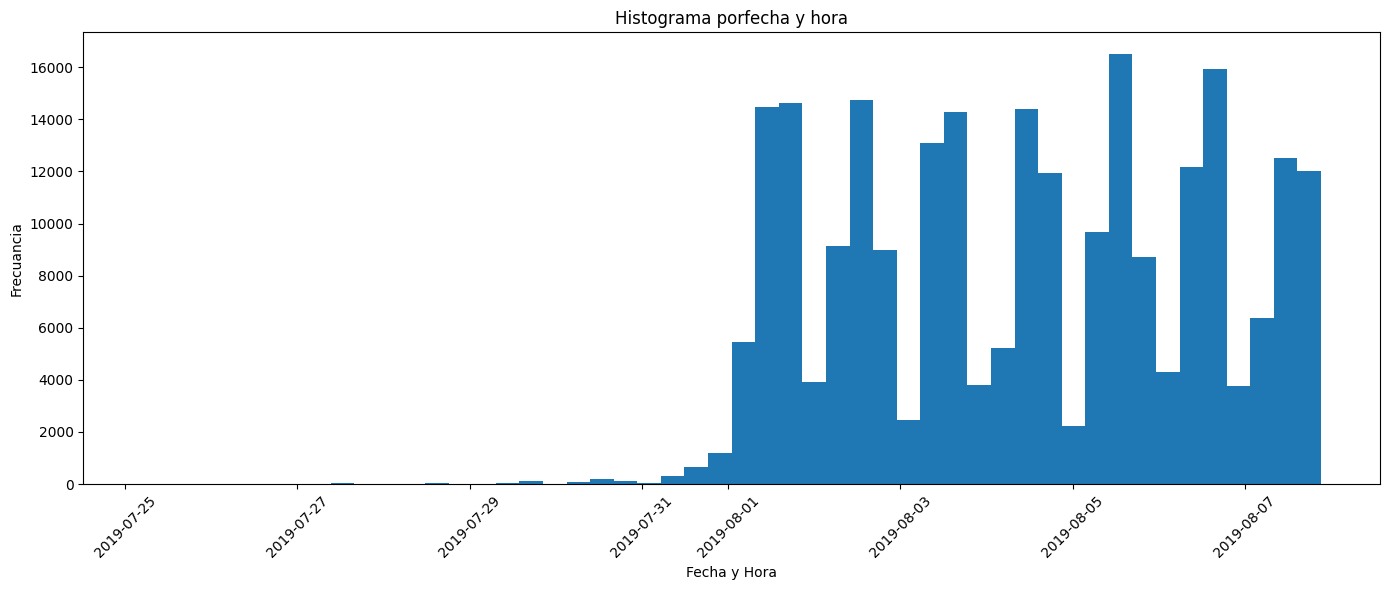

In [ ]:
# histograma por fecha y hora 
plt.figure(figsize=(14, 6))
plt.title('Histograma porfecha y hora')
plt.hist(global_clean['date_event'], bins=50)
plt.xticks(rotation=45)
plt.xlabel('Fecha y Hora')
plt.ylabel('Frecuancia')
plt.tight_layout()
plt.show()

### En el periodo que nos da el histograma los datos comiezan a tener relivancia hasta 2019-02-01, asi que no, no tenenmos datos igualmente completos para todo el periodo.
### Los datos a partir de dicha fecha se ven mas consistentes, el epriodo real de los datos, comienza desde mi punto de vista el dia 2019-08-01, datos anteriores a esta fecha no tinene suficiente relevancia pra ser considerados, asi que defino el el periodo real de los datos es de 2019-08-01 a 2019-08-07.

### No se perdieron gran cantidad de datos, incluso se pueden considerar dias sin actividad, ya que no representan ni la actividad minima en lo que se considera el inicio del periodo, se busca calidad en la muestra no cantidad para realizar una prube exitosa.

In [ ]:
# filtrado de muestra para asegursar calidad en los datos 
muestra_filtrada = global_clean[(global_clean['date_event'] >= '2019-08-01') & (global_clean['date_event']<= '2019-08-07')]

In [ ]:
# se cuenta con usuarios de los 3 grupos?
print("GRUPOS EXPERIMENTALES =",muestra_filtrada['exp_num'].nunique())

GRUPOS EXPERIMENTALES = 3


In [ ]:
#numero de usuarios por grupo 
print("Usuarios por grupo experimental:")
print(muestra_filtrada.groupby('exp_num')['user_id'].nunique())

Usuarios por grupo experimental:
exp_num
246    2420
247    2445
248    2470
Name: user_id, dtype: int64


## Paso numero 4 

In [ ]:
#numero de usuarios en cada experimento y conteo de eventos 
print(muestra_filtrada['exp_num'].value_counts().sort_values())
print(muestra_filtrada['event'].value_counts())

247    66931
246    68690
248    74170
Name: exp_num, dtype: int64
MainScreenAppear           101538
OffersScreenAppear          40393
CartScreenAppear            37249
PaymentScreenSuccessful     29676
Tutorial                      935
Name: event, dtype: int64


In [ ]:
muestra_filtrada.columns

Index(['event', 'user_id', 'hour_event', 'exp_num', 'date_event', 'date'], dtype='object')

In [ ]:
#Frecuencia de eventos 
print("===Analisis de Eventos===")
print("Eventos ordenados por frecuencia")
eventos_por_frecuencia = muestra_filtrada['event'].value_counts()
print(eventos_por_frecuencia)

===Analisis de Eventos===
Eventos ordenados por frecuencia
MainScreenAppear           101538
OffersScreenAppear          40393
CartScreenAppear            37249
PaymentScreenSuccessful     29676
Tutorial                      935
Name: event, dtype: int64


In [ ]:
#Porcentaje de eventos 
print("Porcentaje por evento")
porcentaje_x_evento = (muestra_filtrada['event'].value_counts() / len(muestra_filtrada) * 100).round(2)
print(porcentaje_x_evento)

Porcentaje por evento
MainScreenAppear           48.40
OffersScreenAppear         19.25
CartScreenAppear           17.76
PaymentScreenSuccessful    14.15
Tutorial                    0.45
Name: event, dtype: float64


### Paso 4.1
### El eveno mas frecuente es MainScreenAppear y el menos frecente es Tutorial, MainScreenAppear tiene un porcentaje de 48.40 mientras que Tutorial tenen solo el 0.45

### 4.2 

In [ ]:
# Usuarios por evento 
usuarios_x_evento = muestra_filtrada.groupby('event')['user_id'].nunique().sort_values(ascending=False)
print("Usuarios unicos por evento", usuarios_x_evento)

Usuarios unicos por evento event
MainScreenAppear           7206
OffersScreenAppear         4414
CartScreenAppear           3601
PaymentScreenSuccessful    3418
Tutorial                    775
Name: user_id, dtype: int64


In [ ]:
#Eventos ordenados calculo de proporcion de usuarios que realiazaron la accion al menos 1 vez 
comparacion = pd.DataFrame({
    'total_eventos': muestra_filtrada['event'].value_counts(),
    'usuarios_unicos': usuarios_x_evento
})
comparacion['eventos_por_usuario'] = (comparacion['total_eventos'] / comparacion['usuarios_unicos']).round(2)
print(comparacion)

                         total_eventos  usuarios_unicos  eventos_por_usuario
MainScreenAppear                101538             7206                14.09
OffersScreenAppear               40393             4414                 9.15
CartScreenAppear                 37249             3601                10.34
PaymentScreenSuccessful          29676             3418                 8.68
Tutorial                           935              775                 1.21


### 4.3 
### Orden de las acciones, 1; ingreso a la pagina (pagina principal) 2; pantalla del carrito, 3; pantalla de ofertas, 4 pagina de pago 
### La pantalla de inicio es la que presenta mayor actividad ya que desde allí se realiza todo, pensodo como consumidor, la pantalla de ofertas esta por debajo del carrito, porque podemos pensar, que los usuarios dejan armado su carrito con loq ue ya tienen en mente comrar, y le dan prioridad a lo que necesitan que auna oferta in ncesaria para ellos. Que la pantalla de tutoria tenga un bajo nivel de aqctividad puede sugerir que la panatalla y el diseño es bastante intuitivo, lo cual no dificulta la experiencia del usuario.

### 4.4
### Envudo de eventros para encontrar proporcion de usuarios que pasan de una etapa a la siguiente

In [ ]:
# Crear un conjunto de usuarios por cada evento
users_main = set(muestra_filtrada[muestra_filtrada['event'] == 'MainScreenAppear']['user_id'])
users_cart = set(muestra_filtrada[muestra_filtrada['event'] == 'CartScreenAppear']['user_id'])
users_offers = set(muestra_filtrada[muestra_filtrada['event'] == 'OffersScreenAppear']['user_id'])
users_payment = set(muestra_filtrada[muestra_filtrada['event'] == 'PaymentScreenSuccessful']['user_id'])

In [ ]:
# Intersección de conjuntos - usuarios que hicieron AMBOS eventos
main_to_cart = users_main & users_cart

# Número de usuarios que pasaron de main a cart
print(f"Usuarios que fueron de Main a Cart: {len(main_to_cart)}")

# Proporción de conversión
conversion_rate = len(main_to_cart) / len(users_main)
print(f"Tasa de conversión Main → Cart: {conversion_rate:.2%}")

Usuarios que fueron de Main a Cart: 3488
Tasa de conversión Main → Cart: 48.40%


In [ ]:
cart_to_offers = users_cart & users_offers

# Número de usuarios que pasaron de cart to offers
print(f"Usuarios que fueron de Cart a Offers: {len(cart_to_offers)}")

# Proporción de conversión
conversion_rate = len(cart_to_offers) / len(users_cart)
print(f"Tasa de conversión Main → Cart: {conversion_rate:.2%}")

Usuarios que fueron de Cart a Offers: 3548
Tasa de conversión Main → Cart: 98.53%


In [ ]:
offers_to_payment = users_offers & users_payment

# Número de usuarios que pasaron de offers to payment
print(f"Usuarios que fueron de Offers a Payment: {len(offers_to_payment)}")

# Proporción de conversión
conversion_rate = len(offers_to_payment) / len(users_offers)
print(f"Tasa de conversión Main → Cart: {conversion_rate:.2%}")

Usuarios que fueron de Offers a Payment: 3410
Tasa de conversión Main → Cart: 77.25%


In [ ]:
cart_to_payment = users_cart & users_payment

# Número de usuarios que pasaron de cart to payment 
print(f"Usuarios que fueron de Cart a Payment: {len(cart_to_payment)}")

# Proporción de conversión
conversion_rate = len(cart_to_payment) / len(users_cart)
print(f"Tasa de conversión Main → Cart: {conversion_rate:.2%}")

Usuarios que fueron de Cart a Payment: 3413
Tasa de conversión Main → Cart: 94.78%


In [ ]:
print("=== EMBUDO DE CONVERSIÓN ===")
print(f"1. MainScreen usuarios: {len(users_main):,}")
print(f"2. Main → Cart: {len(main_to_cart):,} usuarios ({len(main_to_cart)/len(users_main):.2%})")
print(f"3. Cart → Offers: {len(cart_to_offers):,} usuarios ({len(cart_to_offers)/len(users_cart):.2%})")
print(f"4. Offers → Payment: {len(offers_to_payment):,} usuarios ({len(offers_to_payment)/len(users_offers):.2%})")
print(f"5. Cart → Payment: {len(cart_to_payment):,} usuarios ({len(cart_to_payment)/len(users_cart):.2%})")

=== EMBUDO DE CONVERSIÓN ===
1. MainScreen usuarios: 7,206
2. Main → Cart: 3,488 usuarios (48.40%)
3. Cart → Offers: 3,548 usuarios (98.53%)
4. Offers → Payment: 3,410 usuarios (77.25%)
5. Cart → Payment: 3,413 usuarios (94.78%)


### 4.5 
### La mitad de usuarios que ven la app, no agregan nada al carrito, pero una vez agregado algo al carrito la mayoria completa la acompra, quiza l a pantalla principal no es suficientemente atractyicva o no muestra buenas ofertas o precios, quiza se deba a la interfaz que puede resultar confuza para lagunos.


### 4.6 

In [ ]:
# Usuarios que hicieron el viaje completo: MainScreen → Payment
complete_journey = users_main & users_payment

# Porcentaje del viaje completo
complete_rate = len(complete_journey) / len(users_main)
print(f"Viaje completo Main → Payment: {complete_rate:.2%}")

Viaje completo Main → Payment: 45.88%


### Casi la mitad de usuarios 45,46% completaron el viaje completo por todas las pantallas, un numero bastante alentador. Esto nos da una pauta para comenzar a mejorar apariencia, oferas e incluso productos para el citio, con la estrategia adecuada este numero puede llegar a crecer aun mas en un futuro cercano.

### Paso 5 

In [ ]:
#5.1 #numero de usuarios en cada experimento 
print(muestra_filtrada['exp_num'].value_counts().sort_values())

247    66931
246    68690
248    74170
Name: exp_num, dtype: int64


In [ ]:
#5.2 # Calcular conversiones por grupo
def analizar_grupo(data, grupo_num):
    grupo_data = data[data['exp_num'] == grupo_num]
    
    users_main = set(grupo_data[grupo_data['event'] == 'MainScreenAppear']['user_id'])
    users_payment = set(grupo_data[grupo_data['event'] == 'PaymentScreenSuccessful']['user_id'])
    
    conversiones = len(users_main & users_payment)
    total = len(users_main)
    tasa = conversiones / total if total > 0 else 0
    
    return conversiones, total, tasa

# Analizar cada grupo
for grupo in [246, 247]:
    conv, total, tasa = analizar_grupo(muestra_filtrada, grupo)
    print(f"Grupo {grupo}: {conv}/{total} = {tasa:.4f}")

Grupo 246: 1119/2377 = 0.4708
Grupo 247: 1081/2406 = 0.4493


In [ ]:
# Datos de los grupos
n_usuarios_A1 = 2377  # usuarios grupo 246
conversiones_A1 = 1119  # conversiones grupo 246
n_usuarios_A2 = 2406  # usuarios grupo 247
conversiones_A2 = 1081  # conversiones grupo 247

# Calcular proporciones
p1 = conversiones_A1 / n_usuarios_A1
p2 = conversiones_A2 / n_usuarios_A2

print(f"Proporción grupo 246: {p1:.4f}")
print(f"Proporción grupo 247: {p2:.4f}")
print(f"Diferencia observada: {p1 - p2:.4f}")

Proporción grupo 246: 0.4708
Proporción grupo 247: 0.4493
Diferencia observada: 0.0215


In [ ]:
# Proporción combinada
p_combined = (conversiones_A1 + conversiones_A2) / (n_usuarios_A1 + n_usuarios_A2)
print(f"Proporción combinada: {p_combined:.4f}")

Proporción combinada: 0.4600


In [ ]:
import math

# Error estándar
se = math.sqrt(p_combined * (1 - p_combined) * (1/n_usuarios_A1 + 1/n_usuarios_A2))
print(f"Error estándar: {se:.6f}")

# Estadístico z
z_stat = (p1 - p2) / se
print(f"Estadístico z: {z_stat:.4f}")

# P-valor para prueba de dos colas
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print(f"P-valor: {p_value:.6f}")

Error estándar: 0.014413
Estadístico z: 1.4895
P-valor: 0.136364


### No hay diferencia estadistica significativa, aunque se obcerva una diferencia de 2.15 %, esta podria deberse simplemente al azar y no a una diferencia real entre los grupos 

### 5.3

In [ ]:
def test_estadistico_evento(muestra_filtrada, evento, grupo1=246, grupo2=247):
    """
    Realiza prueba estadística para comparar proporciones de un evento entre dos grupos
    """
    # Filtrar datos por evento
    datos_evento = muestra_filtrada[muestra_filtrada['event'] == evento]
    
    # Contar usuarios únicos por grupo para este evento
    usuarios_grupo1 = datos_evento[datos_evento['exp_num'] == grupo1]['user_id'].nunique()
    usuarios_grupo2 = datos_evento[datos_evento['exp_num'] == grupo2]['user_id'].nunique()
    
    # Total de usuarios por grupo (todos los usuarios del grupo, no solo los del evento)
    total_grupo1 = muestra_filtrada[muestra_filtrada['exp_num'] == grupo1]['user_id'].nunique()
    total_grupo2 = muestra_filtrada[muestra_filtrada['exp_num'] == grupo2]['user_id'].nunique()
    
    # Calcular proporciones
    p1 = usuarios_grupo1 / total_grupo1
    p2 = usuarios_grupo2 / total_grupo2
    
    # Proporción combinada
    p_combined = (usuarios_grupo1 + usuarios_grupo2) / (total_grupo1 + total_grupo2)
    
    # Error estándar
    import math
    se = math.sqrt(p_combined * (1 - p_combined) * (1/total_grupo1 + 1/total_grupo2))
    
    # Estadístico z
    z_stat = (p1 - p2) / se
    
    # P-valor para prueba de dos colas
    p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
    
    # Mostrar resultados
    print(f"=== EVENTO: {evento} ===")
    print(f"Grupo {grupo1}: {usuarios_grupo1}/{total_grupo1} = {p1:.4f}")
    print(f"Grupo {grupo2}: {usuarios_grupo2}/{total_grupo2} = {p2:.4f}")
    print(f"Diferencia: {p1 - p2:.4f}")
    print(f"Estadístico z: {z_stat:.4f}")
    print(f"P-valor: {p_value:.6f}")
    print(f"Significativo (α=0.05): {'Sí' if p_value < 0.05 else 'No'}")
    print("-" * 50)
    
    return {
        'evento': evento,
        'p1': p1,
        'p2': p2,
        'diferencia': p1 - p2,
        'z_stat': z_stat,
        'p_value': p_value,
        'significativo': p_value < 0.05
    }

In [ ]:
test_estadistico_evento(muestra_filtrada, 'MainScreenAppear')

=== EVENTO: MainScreenAppear ===
Grupo 246: 2377/2420 = 0.9822
Grupo 247: 2406/2445 = 0.9840
Diferencia: -0.0018
Estadístico z: -0.4924
P-valor: 0.622413
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'MainScreenAppear',
 'p1': 0.9822314049586777,
 'p2': 0.9840490797546012,
 'diferencia': -0.0018176747959235406,
 'z_stat': -0.4924335176671393,
 'p_value': 0.6224129095031041,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'OffersScreenAppear')

=== EVENTO: OffersScreenAppear ===
Grupo 246: 1477/2420 = 0.6103
Grupo 247: 1462/2445 = 0.5980
Diferencia: 0.0124
Estadístico z: 0.8825
P-valor: 0.377494
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'OffersScreenAppear',
 'p1': 0.6103305785123967,
 'p2': 0.5979550102249489,
 'diferencia': 0.012375568287447791,
 'z_stat': 0.8825224327841117,
 'p_value': 0.3774943541607674,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'CartScreenAppear')

=== EVENTO: CartScreenAppear ===
Grupo 246: 1217/2420 = 0.5029
Grupo 247: 1190/2445 = 0.4867
Diferencia: 0.0162
Estadístico z: 1.1289
P-valor: 0.258922
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'CartScreenAppear',
 'p1': 0.5028925619834711,
 'p2': 0.4867075664621677,
 'diferencia': 0.016184995521303425,
 'z_stat': 1.1289433147789405,
 'p_value': 0.2589217469508469,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'PaymentScreenSuccessful')

=== EVENTO: PaymentScreenSuccessful ===
Grupo 246: 1157/2420 = 0.4781
Grupo 247: 1114/2445 = 0.4556
Diferencia: 0.0225
Estadístico z: 1.5711
P-valor: 0.116160
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'PaymentScreenSuccessful',
 'p1': 0.478099173553719,
 'p2': 0.4556237218813906,
 'diferencia': 0.022475451672328395,
 'z_stat': 1.5710984936401786,
 'p_value': 0.1161597724607022,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'Tutorial')

=== EVENTO: Tutorial ===
Grupo 246: 253/2420 = 0.1045
Grupo 247: 267/2445 = 0.1092
Diferencia: -0.0047
Estadístico z: -0.5257
P-valor: 0.599130
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'Tutorial',
 'p1': 0.10454545454545454,
 'p2': 0.10920245398773006,
 'diferencia': -0.004656999442275517,
 'z_stat': -0.5256518058318093,
 'p_value': 0.5991301548905126,
 'significativo': False}

### Podemos confirmar que los grupos se dividieron correctamente, ya que los valores p son  >0.05, las diferencias entre las proporciones son pequeñas, ademas de obtener un rsultado 'No signifivo' con la funcion realizada en cada evento.

### 5.4 Comparacion con fuentes alteradas 

In [ ]:
 #Comparar grupo experimental (248) con grupo control (246)
test_estadistico_evento(muestra_filtrada, 'MainScreenAppear', grupo1=248, grupo2=246)

=== EVENTO: MainScreenAppear ===
Grupo 248: 2423/2470 = 0.9810
Grupo 246: 2377/2420 = 0.9822
Diferencia: -0.0013
Estadístico z: -0.3277
P-valor: 0.743153
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'MainScreenAppear',
 'p1': 0.9809716599190283,
 'p2': 0.9822314049586777,
 'diferencia': -0.0012597450396493182,
 'z_stat': -0.3276810848191787,
 'p_value': 0.7431528065858823,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'OffersScreenAppear', grupo1=248, grupo2=246)

=== EVENTO: OffersScreenAppear ===
Grupo 248: 1475/2470 = 0.5972
Grupo 246: 1477/2420 = 0.6103
Diferencia: -0.0132
Estadístico z: -0.9410
P-valor: 0.346712
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'OffersScreenAppear',
 'p1': 0.597165991902834,
 'p2': 0.6103305785123967,
 'diferencia': -0.013164586609562656,
 'z_stat': -0.9409851122634889,
 'p_value': 0.34671248861006987,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'CartScreenAppear', grupo1=248, grupo2=246)

=== EVENTO: CartScreenAppear ===
Grupo 248: 1194/2470 = 0.4834
Grupo 246: 1217/2420 = 0.5029
Diferencia: -0.0195
Estadístico z: -1.3631
P-valor: 0.172854
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'CartScreenAppear',
 'p1': 0.4834008097165992,
 'p2': 0.5028925619834711,
 'diferencia': -0.019491752266871887,
 'z_stat': -1.3630902257346065,
 'p_value': 0.17285407684678433,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'PaymentScreenSuccessful', grupo1=248, grupo2=246)

=== EVENTO: PaymentScreenSuccessful ===
Grupo 248: 1147/2470 = 0.4644
Grupo 246: 1157/2420 = 0.4781
Diferencia: -0.0137
Estadístico z: -0.9614
P-valor: 0.336332
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'PaymentScreenSuccessful',
 'p1': 0.4643724696356275,
 'p2': 0.478099173553719,
 'diferencia': -0.013726703918091498,
 'z_stat': -0.9614381647945486,
 'p_value': 0.3363319025501228,
 'significativo': False}

In [ ]:
test_estadistico_evento(muestra_filtrada, 'Tutorial', grupo1=248, grupo2=246)

=== EVENTO: Tutorial ===
Grupo 248: 255/2470 = 0.1032
Grupo 246: 253/2420 = 0.1045
Diferencia: -0.0013
Estadístico z: -0.1497
P-valor: 0.880985
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'Tutorial',
 'p1': 0.10323886639676114,
 'p2': 0.10454545454545454,
 'diferencia': -0.0013065881486934022,
 'z_stat': -0.14972049733484813,
 'p_value': 0.8809851359279921,
 'significativo': False}

### De igual manera, entre el grupo 248 y 246, podemos confirmar que los grupos se dividieron correctamente, ya que los valores p son  >0.05, las diferencias entre las proporciones son pequeñas, ademas de obtener un rsultado 'No signifivo' con la funcion realizada en cada evento.

In [ ]:
# Comparar grupo experimental (248) con grupo control (247)
test_estadistico_evento(muestra_filtrada, 'MainScreenAppear', grupo1=248, grupo2=247)

=== EVENTO: MainScreenAppear ===
Grupo 248: 2423/2470 = 0.9810
Grupo 247: 2406/2445 = 0.9840
Diferencia: -0.0031
Estadístico z: -0.8227
P-valor: 0.410660
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'MainScreenAppear',
 'p1': 0.9809716599190283,
 'p2': 0.9840490797546012,
 'diferencia': -0.003077419835572859,
 'z_stat': -0.8227323796412476,
 'p_value': 0.4106601977212261,
 'significativo': False}

In [ ]:
# Comparar grupo experimental (248) con grupo control (247)
test_estadistico_evento(muestra_filtrada, 'OffersScreenAppear', grupo1=248, grupo2=247)

=== EVENTO: OffersScreenAppear ===
Grupo 248: 1475/2470 = 0.5972
Grupo 247: 1462/2445 = 0.5980
Diferencia: -0.0008
Estadístico z: -0.0564
P-valor: 0.955024
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'OffersScreenAppear',
 'p1': 0.597165991902834,
 'p2': 0.5979550102249489,
 'diferencia': -0.000789018322114865,
 'z_stat': -0.05639903079693963,
 'p_value': 0.9550239290401548,
 'significativo': False}

In [ ]:
# Comparar grupo experimental (248) con grupo control (247)
test_estadistico_evento(muestra_filtrada, 'CartScreenAppear', grupo1=248, grupo2=247)

=== EVENTO: CartScreenAppear ===
Grupo 248: 1194/2470 = 0.4834
Grupo 247: 1190/2445 = 0.4867
Diferencia: -0.0033
Estadístico z: -0.2319
P-valor: 0.816594
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'CartScreenAppear',
 'p1': 0.4834008097165992,
 'p2': 0.4867075664621677,
 'diferencia': -0.003306756745568462,
 'z_stat': -0.23192775250515682,
 'p_value': 0.8165941287752108,
 'significativo': False}

In [ ]:
# Comparar grupo experimental (248) con grupo control (247)
test_estadistico_evento(muestra_filtrada, 'PaymentScreenSuccessful', grupo1=248, grupo2=247)

=== EVENTO: PaymentScreenSuccessful ===
Grupo 248: 1147/2470 = 0.4644
Grupo 247: 1114/2445 = 0.4556
Diferencia: 0.0087
Estadístico z: 0.6153
P-valor: 0.538349
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'PaymentScreenSuccessful',
 'p1': 0.4643724696356275,
 'p2': 0.4556237218813906,
 'diferencia': 0.008748747754236896,
 'z_stat': 0.6153112053616451,
 'p_value': 0.5383492189000192,
 'significativo': False}

In [ ]:
# Comparar grupo experimental (248) con grupo control (247)
test_estadistico_evento(muestra_filtrada, 'Tutorial', grupo1=248, grupo2=247)

=== EVENTO: Tutorial ===
Grupo 248: 255/2470 = 0.1032
Grupo 247: 267/2445 = 0.1092
Diferencia: -0.0060
Estadístico z: -0.6785
P-valor: 0.497463
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'Tutorial',
 'p1': 0.10323886639676114,
 'p2': 0.10920245398773006,
 'diferencia': -0.005963587590968919,
 'z_stat': -0.6784868247615705,
 'p_value': 0.4974630747412987,
 'significativo': False}

### De igual manera, entre el grupo 248 y 247, podemos confirmar que los grupos se dividieron correctamente, ya que los valores p son >0.05, las diferencias entre las proporciones son pequeñas, ademas de obtener un rsultado 'No signifivo' con la funcion realizada en cada evento.¶

### 5.4

In [ ]:
#comparacion de datos combinados 
def test_estadistico_evento_combinado(muestra_filtrada, evento, grupo1=248, grupos_control=[246, 247]
  ):
    """
    Realiza prueba estadística para comparar proporciones de un evento entre dos grupos combinados 
    """
    # Filtrar datos por evento
    datos_evento = muestra_filtrada[muestra_filtrada['event'] == evento]
    
    # Contar usuarios únicos por grupo para este evento
    usuarios_grupo1 = datos_evento[datos_evento['exp_num'] == grupo1]['user_id'].nunique()
    usuarios_control = datos_evento[datos_evento['exp_num'].isin(grupos_control)]['user_id'].nunique()
    
    # Total de usuarios por grupo (todos los usuarios del grupo, no solo los del evento)
    total_grupo1 = muestra_filtrada[muestra_filtrada['exp_num'] == grupo1]['user_id'].nunique()
    total_control = muestra_filtrada[muestra_filtrada['exp_num'].isin(grupos_control)]['user_id'].nunique()
    
    # Calcular proporciones
    p1 = usuarios_grupo1 / total_grupo1
    p2 = usuarios_control / total_control
    
    # Proporción combinada
    p_combined = (usuarios_grupo1 + usuarios_control) / (total_grupo1 + total_control)
    
    # Error estándar
    import math
    se = math.sqrt(p_combined * (1 - p_combined) * (1/total_grupo1 + 1/total_control))
    
    # Estadístico z
    z_stat = (p1 - p2) / se
    
    # P-valor para prueba de dos colas
    p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
    
    # Mostrar resultados
    print(f"=== EVENTO: {evento} ===")
    print(f"Grupo {grupo1}: {usuarios_grupo1}/{total_grupo1} = {p1:.4f}")
    print(f"Grupo control {grupos_control}: {usuarios_control}/{total_control} = {p2:.4f}")
    print(f"Diferencia: {p1 - p2:.4f}")
    print(f"Estadístico z: {z_stat:.4f}")
    print(f"P-valor: {p_value:.6f}")
    print(f"Significativo (α=0.05): {'Sí' if p_value < 0.05 else 'No'}")
    print("-" * 50)
    
    return {
        'evento': evento,
        'p1': p1,
        'p2': p2,
        'diferencia': p1 - p2,
        'z_stat': z_stat,
        'p_value': p_value,
        'significativo': p_value < 0.05
    }

In [ ]:
muestra_filtrada['event'].value_counts()

MainScreenAppear           101538
OffersScreenAppear          40393
CartScreenAppear            37249
PaymentScreenSuccessful     29676
Tutorial                      935
Name: event, dtype: int64

In [ ]:
test_estadistico_evento_combinado(muestra_filtrada, 'MainScreenAppear' ,grupo1=248, grupos_control=[246, 247])

=== EVENTO: MainScreenAppear ===
Grupo 248: 2423/2470 = 0.9810
Grupo control [246, 247]: 4783/4865 = 0.9831
Diferencia: -0.0022
Estadístico z: -0.6692
P-valor: 0.503366
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'MainScreenAppear',
 'p1': 0.9809716599190283,
 'p2': 0.9831449126413155,
 'diferencia': -0.002173252722287189,
 'z_stat': -0.6692035039888853,
 'p_value': 0.5033656713596373,
 'significativo': False}

In [ ]:
test_estadistico_evento_combinado(muestra_filtrada, 'OffersScreenAppear' ,grupo1=248, grupos_control=[246, 247])

=== EVENTO: OffersScreenAppear ===
Grupo 248: 1475/2470 = 0.5972
Grupo control [246, 247]: 2939/4865 = 0.6041
Diferencia: -0.0069
Estadístico z: -0.5742
P-valor: 0.565817
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'OffersScreenAppear',
 'p1': 0.597165991902834,
 'p2': 0.6041109969167523,
 'diferencia': -0.0069450050139182595,
 'z_stat': -0.5742229933076888,
 'p_value': 0.5658169116802043,
 'significativo': False}

In [ ]:
test_estadistico_evento_combinado(muestra_filtrada, 'CartScreenAppear' ,grupo1=248, grupos_control=[246, 247])

=== EVENTO: CartScreenAppear ===
Grupo 248: 1194/2470 = 0.4834
Grupo control [246, 247]: 2407/4865 = 0.4948
Diferencia: -0.0114
Estadístico z: -0.9196
P-valor: 0.357802
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'CartScreenAppear',
 'p1': 0.4834008097165992,
 'p2': 0.4947584789311408,
 'diferencia': -0.011357669214541566,
 'z_stat': -0.9195608149415888,
 'p_value': 0.35780231167255594,
 'significativo': False}

In [ ]:
test_estadistico_evento_combinado(muestra_filtrada, 'PaymentScreenSuccessful' ,grupo1=248, grupos_control=[246, 247])

=== EVENTO: PaymentScreenSuccessful ===
Grupo 248: 1147/2470 = 0.4644
Grupo control [246, 247]: 2271/4865 = 0.4668
Diferencia: -0.0024
Estadístico z: -0.1973
P-valor: 0.843619
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'PaymentScreenSuccessful',
 'p1': 0.4643724696356275,
 'p2': 0.4668036998972251,
 'diferencia': -0.0024312302615975834,
 'z_stat': -0.19726645306041568,
 'p_value': 0.8436190300795001,
 'significativo': False}

In [ ]:
test_estadistico_evento_combinado(muestra_filtrada, 'Tutorial' ,grupo1=248, grupos_control=[246, 247])

=== EVENTO: Tutorial ===
Grupo 248: 255/2470 = 0.1032
Grupo control [246, 247]: 520/4865 = 0.1069
Diferencia: -0.0036
Estadístico z: -0.4802
P-valor: 0.631080
Significativo (α=0.05): No
--------------------------------------------------


{'evento': 'Tutorial',
 'p1': 0.10323886639676114,
 'p2': 0.10688591983556012,
 'diferencia': -0.0036470534387989806,
 'z_stat': -0.48020791496468374,
 'p_value': 0.6310795593442573,
 'significativo': False}

### No hay diferencia estadísticamente significativa entre los grupos porque todos los valores p son mayores a 0.05.

### Esto significa que:

### Las fuentes nuevas (grupo 248) no mejoraron significativamente las conversiones
### Los grupos de control se comportaron de manera similar entre sí
### La diferencia observada puede deberse al azar, no a un efecto real

### Como recomendacion queda,revizar el diseño de la pantalla Tutorial, mejorar en ofrecer y anunciar mejores ofertas en la pantalla Offers y si esposible buscar ingresar publicidad o alguna clase de beneficio para quienes despuesde de agregar a Cart vallan directo a Payment

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br>
<b>Éxito</b> - La comparación entre grupos y la interpretación de los resultados estadísticos están explicadas con claridad y coherencia. El análisis transmite una comprensión sólida sobre cómo validar experimentalmente cambios en una aplicación a partir de evidencia cuantitativa.
</div>


In [ ]:
from statsmodels.stats.multitest import multipletests

p_values = [
    # Comparaciones 246 vs 247 (5 eventos)
    0.622413,  # MainScreenAppear
    0.377494,  # OffersScreenAppear  
    0.258922,  # CartScreenAppear
    0.116160,  # PaymentScreenSuccessful
    0.599130,  # Tutorial
    
    # Comparaciones 248 vs 246 (5 eventos)
    0.743153,  # MainScreenAppear
    0.346712,  # OffersScreenAppear
    0.172854,  # CartScreenAppear
    0.336332,  # PaymentScreenSuccessful
    0.880985,  # Tutorial
    
    # Comparaciones 248 vs 247 (5 eventos)
    0.410660,  # MainScreenAppear
    0.955024,  # OffersScreenAppear
    0.816594,  # CartScreenAppear
    0.538349,  # PaymentScreenSuccessful
    0.497463,  # Tutorial
    
    # Comparaciones 248 vs (246+247) (5 eventos)
    0.503366,  # MainScreenAppear
    0.565817,  # OffersScreenAppear
    0.357802,  # CartScreenAppear
    0.843619,  # PaymentScreenSuccessful
    0.631080   # Tutorial
]
rechazo, p_corregidos, _, _ = multipletests(p_values, alpha=0.05, method='bonferroni')
print(p_corregidos)  
print(rechazo)       # [True, False, False] Solo el primero sigue siendo significativo

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
[False False False False False False False False False False False False
 False False False False False False False False]


### Antes de la corrección: Pensabas que no había diferencias significativas
### Después de la corrección: Confirmas que definitivamente no hay diferencias significativas

### Conclusión final:
### Con un α ajustado de 0.05/20 = 0.0025, ninguna de tus pruebas alcanza este nivel de significancia más estricto.

### Entrega de resultados de anlisis tests A/A AA/B Junir Data Analist Cesar Rodriguez